# ClearBank — Análise Financeira com Python

Notebook que lê e valida o arquivo `transacoes.csv`, agrupa as transações por mês, calcula métricas financeiras, sinaliza transações suspeitas, exibe um relatório formatado e exporta o resultado em `relatorio.json`.

## Instruções

Antes de executar, o arquivo `transacoes.csv` deve estar na mesma pasta deste notebook, com as colunas:

`id, data, cliente_id, tipo, valor, descricao, categoria`

O arquivo de teste contém:
- **18 registros válidos** distribuídos entre janeiro e abril de 2026;
- **10 registros inválidos**, um para cada regra de validação (id vazio, id não numérico, cliente vazio, data em formato errado, data inexistente, tipo inválido, valor não numérico, valor zero, valor negativo e id duplicado);
- **3 transações acima de R$ 10.000,00** e uma exatamente no limite (que **não** deve ser sinalizada).

Execute as células em ordem: cada seção tem um teste rápido ao final. A **Célula de Execução Principal**, no fim do notebook, roda o fluxo completo.

## Configuração

In [1]:
import csv
import json
from datetime import datetime

CAMINHO_CSV = "transacoes.csv"
CAMINHO_JSON = "relatorio.json"
FORMATO_DATA = "%Y-%m-%d"
TIPOS_VALIDOS = ("credito", "debito")
LIMITE_SUSPEITO = 10000.00

print(f"Configuração carregada | LIMITE_SUSPEITO = {LIMITE_SUSPEITO}")

Configuração carregada | LIMITE_SUSPEITO = 10000.0


## 1. Leitura do CSV

Leitura com o módulo `csv` nativo usando `csv.DictReader`, que entrega cada linha como dicionário indexado pelo nome da coluna. Se o arquivo não existir, o erro é tratado e a função devolve uma lista vazia em vez de interromper o programa.

In [2]:
def ler_transacoes(caminho):
    """Lê o CSV e retorna a lista de transações brutas (um dict por linha)."""
    try:
        with open(caminho, encoding="utf-8", newline="") as arquivo:
            return list(csv.DictReader(arquivo))
    except FileNotFoundError:
        print(f"Erro: arquivo '{caminho}' não encontrado.")
        return []


print("Função definida: ler_transacoes()")

Função definida: ler_transacoes()


In [3]:
# Teste rápido — leitura
brutas = ler_transacoes(CAMINHO_CSV)
print(f"Linhas lidas: {len(brutas)}")
print(f"Primeira linha: {brutas[0]}")

print("\nArquivo inexistente:")
print(f"Retorno: {ler_transacoes('nao_existe.csv')}")

Linhas lidas: 28
Primeira linha: {'id': '1', 'data': '2026-01-05', 'cliente_id': 'CLI001', 'tipo': 'credito', 'valor': '3500.00', 'descricao': 'Salário janeiro', 'categoria': 'salario'}

Arquivo inexistente:
Erro: arquivo 'nao_existe.csv' não encontrado.
Retorno: []


## 2. Validação e limpeza

Cada campo tem sua própria função de conversão, que devolve o valor convertido ou `None` quando o dado é inválido. `validar_transacao()` combina essas funções para uma linha, e `limpar_transacoes()` aplica a validação em todas as linhas, descartando também ids duplicados (mantém a primeira ocorrência).

Linhas inválidas são descartadas sem interromper o processamento.

In [4]:
def obter_campo(linha, coluna):
    """Retorna o campo sem espaços nas pontas ('' se ausente)."""
    return (linha.get(coluna) or "").strip()


def converter_id(texto):
    """Converte o id para int. Retorna None se vazio ou não numérico."""
    if not texto.isdigit():
        return None
    return int(texto)


def converter_valor(texto):
    """Converte o valor para float. Retorna None se não numérico ou <= 0."""
    try:
        valor = float(texto)
    except ValueError:
        return None
    return valor if valor > 0 else None


def converter_data(texto):
    """Converte AAAA-MM-DD para datetime. Retorna None se inválida."""
    try:
        data = datetime.strptime(texto, FORMATO_DATA)
    except ValueError:
        return None
    # strptime aceita '2026-1-5'; exige o formato exato com zeros
    return data if data.strftime(FORMATO_DATA) == texto else None


print("Funções definidas: obter_campo(), converter_id(), converter_valor(), converter_data()")

Funções definidas: obter_campo(), converter_id(), converter_valor(), converter_data()


In [5]:
def validar_transacao(linha):
    """Valida uma linha bruta. Retorna o registro limpo ou None."""
    id_transacao = converter_id(obter_campo(linha, "id"))
    data = converter_data(obter_campo(linha, "data"))
    valor = converter_valor(obter_campo(linha, "valor"))
    cliente = obter_campo(linha, "cliente_id")
    tipo = obter_campo(linha, "tipo")

    if None in (id_transacao, data, valor) or not cliente or tipo not in TIPOS_VALIDOS:
        return None

    return {
        "id": id_transacao,
        "data": data,
        "cliente_id": cliente,
        "tipo": tipo,
        "valor": valor,
        "descricao": obter_campo(linha, "descricao"),
        "categoria": obter_campo(linha, "categoria"),
    }


def limpar_transacoes(brutas):
    """Valida todas as linhas e descarta inválidas e ids duplicados."""
    validas = []
    ids_vistos = set()
    for linha in brutas:
        registro = validar_transacao(linha)
        if registro is None or registro["id"] in ids_vistos:
            continue
        ids_vistos.add(registro["id"])
        validas.append(registro)
    return validas, len(brutas) - len(validas)


def exibir_resumo_limpeza(total_lidas, total_validas, total_invalidas):
    """Imprime o resumo da etapa de limpeza."""
    print(f"Total de linhas lidas: {total_lidas}")
    print(f"Linhas válidas: {total_validas}")
    print(f"Linhas inválidas: {total_invalidas}")


print("Funções definidas: validar_transacao(), limpar_transacoes(), exibir_resumo_limpeza()")

Funções definidas: validar_transacao(), limpar_transacoes(), exibir_resumo_limpeza()


In [6]:
# Teste rápido — funções de conversão
casos = [
    ("converter_id('12')", converter_id("12"), 12),
    ("converter_id('')", converter_id(""), None),
    ("converter_id('abc')", converter_id("abc"), None),
    ("converter_valor('180.50')", converter_valor("180.50"), 180.50),
    ("converter_valor('abc')", converter_valor("abc"), None),
    ("converter_valor('0')", converter_valor("0"), None),
    ("converter_valor('-50')", converter_valor("-50"), None),
    ("converter_data('2026-01-05')", converter_data("2026-01-05"), datetime(2026, 1, 5)),
    ("converter_data('05/03/2026')", converter_data("05/03/2026"), None),
    ("converter_data('2026-13-40')", converter_data("2026-13-40"), None),
    ("converter_data('2026-1-5')", converter_data("2026-1-5"), None),
]
for descricao, obtido, esperado in casos:
    status = "OK  " if obtido == esperado else "FALHOU"
    print(f"[{status}] {descricao} -> {obtido}")

[OK  ] converter_id('12') -> 12
[OK  ] converter_id('') -> None
[OK  ] converter_id('abc') -> None
[OK  ] converter_valor('180.50') -> 180.5
[OK  ] converter_valor('abc') -> None
[OK  ] converter_valor('0') -> None
[OK  ] converter_valor('-50') -> None
[OK  ] converter_data('2026-01-05') -> 2026-01-05 00:00:00
[OK  ] converter_data('05/03/2026') -> None
[OK  ] converter_data('2026-13-40') -> None
[OK  ] converter_data('2026-1-5') -> None


In [7]:
# Teste rápido — validação linha a linha e resumo da limpeza
validas, total_invalidas = limpar_transacoes(brutas)

print("Linhas descartadas:")
ids_vistos = set()
for linha in brutas:
    registro = validar_transacao(linha)
    if registro is None:
        print(f"  inválida  -> {linha}")
    elif registro["id"] in ids_vistos:
        print(f"  duplicada -> {linha}")
    else:
        ids_vistos.add(registro["id"])

print()
exibir_resumo_limpeza(len(brutas), len(validas), total_invalidas)

Linhas descartadas:
  inválida  -> {'id': '', 'data': '2026-01-10', 'cliente_id': 'CLI002', 'tipo': 'debito', 'valor': '50.00', 'descricao': 'Sem id', 'categoria': 'compra'}
  inválida  -> {'id': 'abc', 'data': '2026-01-18', 'cliente_id': 'CLI001', 'tipo': 'debito', 'valor': '30.00', 'descricao': 'Id não numérico', 'categoria': 'compra'}
  inválida  -> {'id': '19', 'data': '2026-02-07', 'cliente_id': '', 'tipo': 'debito', 'valor': '200.00', 'descricao': 'Sem cliente', 'categoria': 'transferencia'}
  duplicada -> {'id': '7', 'data': '2026-02-10', 'cliente_id': 'CLI003', 'tipo': 'debito', 'valor': '320.00', 'descricao': 'Conta de luz', 'categoria': 'conta'}
  inválida  -> {'id': '20', 'data': '05/03/2026', 'cliente_id': 'CLI003', 'tipo': 'debito', 'valor': '75.00', 'descricao': 'Data no formato errado', 'categoria': 'compra'}
  inválida  -> {'id': '22', 'data': '2026-03-18', 'cliente_id': 'CLI004', 'tipo': 'pix', 'valor': '150.00', 'descricao': 'Tipo inválido', 'categoria': 'transferenci

## 3. Datas

As datas já chegam como `datetime` (convertidas com `strptime` na validação). Aqui extraímos o mês no formato `AAAA-MM` com `strftime` e calculamos o período coberto pelos dados.

In [8]:
def extrair_mes(data):
    """Retorna o mês da data no formato AAAA-MM."""
    return data.strftime("%Y-%m")


def calcular_periodo(transacoes):
    """Retorna início, fim e dias entre a transação mais antiga e a mais recente."""
    datas = [t["data"] for t in transacoes]
    inicio, fim = min(datas), max(datas)
    return {
        "inicio": inicio.strftime(FORMATO_DATA),
        "fim": fim.strftime(FORMATO_DATA),
        "dias": (fim - inicio).days,
    }


print("Funções definidas: extrair_mes(), calcular_periodo()")

Funções definidas: extrair_mes(), calcular_periodo()


In [9]:
# Teste rápido — datas
print(f"Mês de 2026-01-05: {extrair_mes(datetime(2026, 1, 5))}")
print(f"Período: {calcular_periodo(validas)}")

Mês de 2026-01-05: 2026-01
Período: {'inicio': '2026-01-05', 'fim': '2026-04-28', 'dias': 113}


## 4. Agrupamento mensal, métricas e suspeitas

As transações válidas são agrupadas num dicionário com o mês como chave. Para cada mês calculamos quantidade, totais de crédito e débito, saldo, média, maior e menor valor. Transações com valor **acima** de `LIMITE_SUSPEITO` são separadas numa lista própria.

`gerar_relatorio()` monta um dicionário já no formato do JSON final, que também é usado pela exibição no terminal.

In [10]:
def agrupar_por_mes(transacoes):
    """Agrupa as transações num dict {mes: [transacoes]} em ordem cronológica."""
    grupos = {}
    for transacao in sorted(transacoes, key=lambda t: t["data"]):
        mes = extrair_mes(transacao["data"])
        grupos.setdefault(mes, []).append(transacao)
    return grupos


def calcular_metricas_mes(transacoes_mes):
    """Calcula as métricas financeiras de um mês."""
    valores = [t["valor"] for t in transacoes_mes]
    credito = sum(t["valor"] for t in transacoes_mes if t["tipo"] == "credito")
    debito = sum(t["valor"] for t in transacoes_mes if t["tipo"] == "debito")
    return {
        "quantidade": len(transacoes_mes),
        "total_credito": round(credito, 2),
        "total_debito": round(debito, 2),
        "saldo": round(credito - debito, 2),
        "media": round(sum(valores) / len(valores), 2),
        "maior_valor": max(valores),
        "menor_valor": min(valores),
    }


def identificar_suspeitas(transacoes):
    """Retorna as transações com valor acima de LIMITE_SUSPEITO."""
    return [
        {
            "id": t["id"],
            "cliente_id": t["cliente_id"],
            "data": t["data"].strftime(FORMATO_DATA),
            "valor": t["valor"],
        }
        for t in transacoes
        if t["valor"] > LIMITE_SUSPEITO
    ]


def gerar_relatorio(validas, total_invalidas):
    """Agrupa os dados e calcula as métricas. Retorna o relatório completo."""
    grupos = agrupar_por_mes(validas)
    return {
        "gerado_em": datetime.now().strftime(FORMATO_DATA),
        "periodo": calcular_periodo(validas),
        "total_transacoes_validas": len(validas),
        "total_transacoes_invalidas": total_invalidas,
        "resumo_mensal": {mes: calcular_metricas_mes(ts) for mes, ts in grupos.items()},
        "transacoes_suspeitas": identificar_suspeitas(validas),
    }


print("Funções definidas: agrupar_por_mes(), calcular_metricas_mes(), identificar_suspeitas(), gerar_relatorio()")

Funções definidas: agrupar_por_mes(), calcular_metricas_mes(), identificar_suspeitas(), gerar_relatorio()


In [11]:
# Teste rápido — métricas e suspeitas
relatorio_teste = gerar_relatorio(validas, total_invalidas)
for mes, metricas in relatorio_teste["resumo_mensal"].items():
    print(mes, metricas)

print("\nSuspeitas:")
for suspeita in relatorio_teste["transacoes_suspeitas"]:
    print(" ", suspeita)

# O id 11 tem valor exatamente igual ao limite e NÃO pode ser suspeito
ids_suspeitos = [s["id"] for s in relatorio_teste["transacoes_suspeitas"]]
print(f"\nid 11 (R$ 10.000,00 exatos) marcado como suspeito? {11 in ids_suspeitos}")

2026-01 {'quantidade': 5, 'total_credito': 16000.0, 'total_debito': 1470.4, 'saldo': 14529.6, 'media': 3494.08, 'maior_valor': 12500.0, 'menor_valor': 89.9}
2026-02 {'quantidade': 4, 'total_credito': 18500.0, 'total_debito': 770.75, 'saldo': 17729.25, 'media': 4817.69, 'maior_valor': 15000.0, 'menor_valor': 320.0}
2026-03 {'quantidade': 4, 'total_credito': 3500.0, 'total_debito': 10739.9, 'saldo': -7239.9, 'media': 3559.97, 'maior_valor': 10000.0, 'menor_valor': 99.9}
2026-04 {'quantidade': 5, 'total_credito': 9500.0, 'total_debito': 22215.3, 'saldo': -12715.3, 'media': 6343.06, 'maior_valor': 22000.0, 'menor_valor': 215.3}

Suspeitas:
  {'id': 4, 'cliente_id': 'CLI002', 'data': '2026-01-22', 'valor': 12500.0}
  {'id': 8, 'cliente_id': 'CLI004', 'data': '2026-02-14', 'valor': 15000.0}
  {'id': 15, 'cliente_id': 'CLI005', 'data': '2026-04-07', 'valor': 22000.0}

id 11 (R$ 10.000,00 exatos) marcado como suspeito? False


## 5. Exibição formatada no terminal

Valores monetários no padrão brasileiro (`R$ 1.234,56`). O relatório é dividido em cabeçalho, resumo mensal e transações suspeitas, cada parte com sua função.

In [12]:
def formatar_moeda(valor):
    """Formata um número como moeda brasileira: R$ 1.234,56."""
    texto = f"{abs(valor):,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
    sinal = "-" if valor < 0 else ""
    return f"{sinal}R$ {texto}"


def exibir_cabecalho(relatorio):
    """Exibe período analisado e totais de transações."""
    periodo = relatorio["periodo"]
    print("===== ANÁLISE FINANCEIRA — CLEARBANK =====")
    print(f"Período analisado: {periodo['inicio']} → {periodo['fim']} ({periodo['dias']} dias)")
    print(f"Transações válidas:   {relatorio['total_transacoes_validas']}")
    print(f"Transações inválidas: {relatorio['total_transacoes_invalidas']}")


def exibir_resumo_mensal(resumo_mensal):
    """Exibe as métricas de cada mês."""
    print("\n===== RELATÓRIO MENSAL =====")
    for mes, m in resumo_mensal.items():
        print(f"\nMês: {mes}")
        print(f"  Transações:    {m['quantidade']}")
        print(f"  Total crédito: {formatar_moeda(m['total_credito'])}")
        print(f"  Total débito:  {formatar_moeda(m['total_debito'])}")
        print(f"  Saldo:         {formatar_moeda(m['saldo'])}")
        print(f"  Média:         {formatar_moeda(m['media'])}")
        print(f"  Maior valor:   {formatar_moeda(m['maior_valor'])}")
        print(f"  Menor valor:   {formatar_moeda(m['menor_valor'])}")


def exibir_suspeitas(suspeitas):
    """Exibe as transações acima do limite, ou aviso se não houver."""
    print("\n===== TRANSAÇÕES SUSPEITAS =====")
    if not suspeitas:
        print("Nenhuma transação suspeita encontrada.")
    for s in suspeitas:
        print(f"ID: {s['id']} | Cliente: {s['cliente_id']} | Data: {s['data']} | Valor: {formatar_moeda(s['valor'])}")


def exibir_relatorio(relatorio):
    """Formata e imprime o relatório completo."""
    exibir_cabecalho(relatorio)
    exibir_resumo_mensal(relatorio["resumo_mensal"])
    exibir_suspeitas(relatorio["transacoes_suspeitas"])


print("Funções definidas: formatar_moeda(), exibir_cabecalho(), exibir_resumo_mensal(), exibir_suspeitas(), exibir_relatorio()")

Funções definidas: formatar_moeda(), exibir_cabecalho(), exibir_resumo_mensal(), exibir_suspeitas(), exibir_relatorio()


In [13]:
# Teste rápido — formatação de moeda e caso sem suspeitas
for valor in (180.5, 3319.5, 15000, 1234567.891, -7239.9):
    print(f"{valor} -> {formatar_moeda(valor)}")

exibir_suspeitas([])

180.5 -> R$ 180,50
3319.5 -> R$ 3.319,50
15000 -> R$ 15.000,00
1234567.891 -> R$ 1.234.567,89
-7239.9 -> -R$ 7.239,90

===== TRANSAÇÕES SUSPEITAS =====
Nenhuma transação suspeita encontrada.


## 6. Exportação em JSON

O relatório é salvo em `relatorio.json` com `ensure_ascii=False` (mantém acentos) e `indent=2` (legível).

In [14]:
def salvar_json(relatorio, caminho):
    """Salva o relatório em JSON. Retorna True se salvou com sucesso."""
    try:
        with open(caminho, "w", encoding="utf-8") as arquivo:
            json.dump(relatorio, arquivo, ensure_ascii=False, indent=2)
    except OSError as erro:
        print(f"Erro ao salvar '{caminho}': {erro}")
        return False
    print(f"\nRelatório salvo em '{caminho}'.")
    return True


print("Função definida: salvar_json()")

Função definida: salvar_json()


## Célula de Execução Principal

Executa o fluxo completo: leitura → validação → métricas → relatório no terminal → `relatorio.json`.

In [15]:
def main():
    """Executa a análise completa das transações."""
    brutas = ler_transacoes(CAMINHO_CSV)
    if not brutas:
        print("Nenhuma transação para processar.")
        return None

    validas, total_invalidas = limpar_transacoes(brutas)
    exibir_resumo_limpeza(len(brutas), len(validas), total_invalidas)
    if not validas:
        print("Nenhuma transação válida encontrada.")
        return None

    relatorio = gerar_relatorio(validas, total_invalidas)
    print()
    exibir_relatorio(relatorio)
    salvar_json(relatorio, CAMINHO_JSON)
    return relatorio


relatorio = main()

Total de linhas lidas: 28
Linhas válidas: 18
Linhas inválidas: 10

===== ANÁLISE FINANCEIRA — CLEARBANK =====
Período analisado: 2026-01-05 → 2026-04-28 (113 dias)
Transações válidas:   18
Transações inválidas: 10

===== RELATÓRIO MENSAL =====

Mês: 2026-01
  Transações:    5
  Total crédito: R$ 16.000,00
  Total débito:  R$ 1.470,40
  Saldo:         R$ 14.529,60
  Média:         R$ 3.494,08
  Maior valor:   R$ 12.500,00
  Menor valor:   R$ 89,90

Mês: 2026-02
  Transações:    4
  Total crédito: R$ 18.500,00
  Total débito:  R$ 770,75
  Saldo:         R$ 17.729,25
  Média:         R$ 4.817,69
  Maior valor:   R$ 15.000,00
  Menor valor:   R$ 320,00

Mês: 2026-03
  Transações:    4
  Total crédito: R$ 3.500,00
  Total débito:  R$ 10.739,90
  Saldo:         -R$ 7.239,90
  Média:         R$ 3.559,97
  Maior valor:   R$ 10.000,00
  Menor valor:   R$ 99,90

Mês: 2026-04
  Transações:    5
  Total crédito: R$ 9.500,00
  Total débito:  R$ 22.215,30
  Saldo:         -R$ 12.715,30
  Média:     

In [16]:
# Conferência — conteúdo do relatorio.json gerado
with open(CAMINHO_JSON, encoding="utf-8") as arquivo:
    print(arquivo.read())

{
  "gerado_em": "2026-10-21",
  "periodo": {
    "inicio": "2026-01-05",
    "fim": "2026-04-28",
    "dias": 113
  },
  "total_transacoes_validas": 18,
  "total_transacoes_invalidas": 10,
  "resumo_mensal": {
    "2026-01": {
      "quantidade": 5,
      "total_credito": 16000.0,
      "total_debito": 1470.4,
      "saldo": 14529.6,
      "media": 3494.08,
      "maior_valor": 12500.0,
      "menor_valor": 89.9
    },
    "2026-02": {
      "quantidade": 4,
      "total_credito": 18500.0,
      "total_debito": 770.75,
      "saldo": 17729.25,
      "media": 4817.69,
      "maior_valor": 15000.0,
      "menor_valor": 320.0
    },
    "2026-03": {
      "quantidade": 4,
      "total_credito": 3500.0,
      "total_debito": 10739.9,
      "saldo": -7239.9,
      "media": 3559.97,
      "maior_valor": 10000.0,
      "menor_valor": 99.9
    },
    "2026-04": {
      "quantidade": 5,
      "total_credito": 9500.0,
      "total_debito": 22215.3,
      "saldo": -12715.3,
      "media": 6343.0

## 7. (Opcional) Análise com pandas

Versão alternativa da leitura e do agrupamento, no arquivo separado `analise_pandas.py`: carrega com `pd.read_csv()`, aplica as mesmas regras de validação, agrupa por mês com `groupby` e compara o resultado com o `resumo_mensal` do `relatorio.json` gerado acima. Os valores devem ser idênticos.

> Requer o `relatorio.json` gerado pela Célula de Execução Principal. No Colab, envie também o `analise_pandas.py` para a sessão.

In [17]:
%run analise_pandas.py

Total de linhas lidas: 28
Linhas válidas: 18
Linhas inválidas: 10

===== RESUMO MENSAL (pandas) =====
         quantidade  total_credito  total_debito     saldo    media  maior_valor  menor_valor
mes                                                                                          
2026-01           5        16000.0       1470.40  14529.60  3494.08      12500.0         89.9
2026-02           4        18500.0        770.75  17729.25  4817.69      15000.0        320.0
2026-03           4         3500.0      10739.90  -7239.90  3559.97      10000.0         99.9
2026-04           5         9500.0      22215.30 -12715.30  6343.06      22000.0        215.3

===== COMPARAÇÃO COM A SOLUÇÃO NATIVA =====
Resultados idênticos: pandas e solução nativa produzem os mesmos valores.


## 8. (Opcional) Visualização com matplotlib

Gráfico de barras empilhadas com crédito e débito por mês, salvo como `grafico.png`.

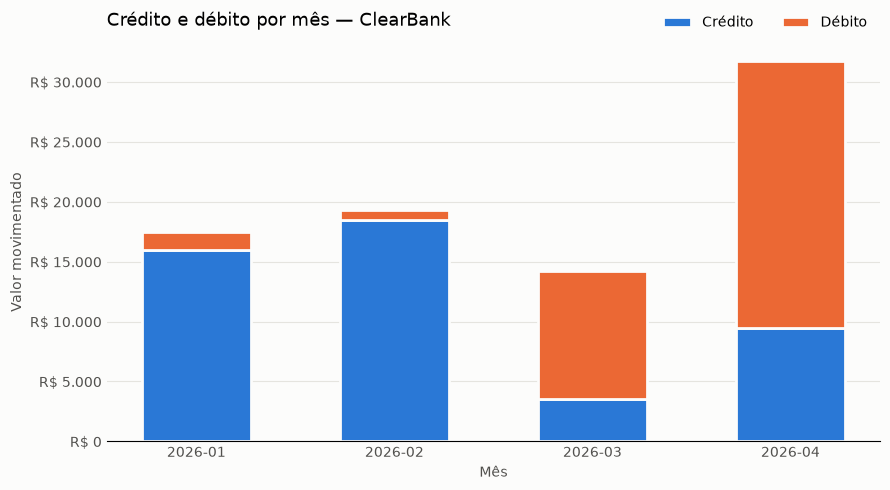

Gráfico salvo em 'grafico.png'.


In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

CAMINHO_GRAFICO = "grafico.png"
COR_CREDITO = "#2a78d6"
COR_DEBITO = "#eb6834"
COR_FUNDO = "#fcfcfb"
COR_TEXTO = "#52514e"


def gerar_grafico(resumo_mensal, caminho):
    """Gera e salva o gráfico de barras empilhadas de crédito e débito por mês."""
    meses = list(resumo_mensal)
    creditos = [resumo_mensal[m]["total_credito"] for m in meses]
    debitos = [resumo_mensal[m]["total_debito"] for m in meses]

    fig, ax = plt.subplots(figsize=(9, 5), facecolor=COR_FUNDO)
    ax.set_facecolor(COR_FUNDO)
    estilo = {"width": 0.55, "edgecolor": COR_FUNDO, "linewidth": 2}
    ax.bar(meses, creditos, color=COR_CREDITO, label="Crédito", **estilo)
    ax.bar(meses, debitos, bottom=creditos, color=COR_DEBITO, label="Débito", **estilo)

    ax.set_title("Crédito e débito por mês — ClearBank", loc="left", fontsize=13, pad=12)
    ax.set_xlabel("Mês", color=COR_TEXTO)
    ax.set_ylabel("Valor movimentado", color=COR_TEXTO)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: formatar_moeda(v)[:-3]))
    ax.grid(axis="y", color="#e5e4df", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=COR_TEXTO, length=0)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncol=2)

    fig.tight_layout()
    fig.savefig(caminho, dpi=150, facecolor=COR_FUNDO)
    plt.show()
    print(f"Gráfico salvo em '{caminho}'.")


gerar_grafico(relatorio["resumo_mensal"], CAMINHO_GRAFICO)